# End-to-End MLOps Crop Classification Pipeline (Image Modality Extension)

### Extension from Intro to Machine Learning Summative
In our Intro to Machine Learning module summative, we solved **7-class Crop Classification** using **174 tabular fused optical-radar sensor features** (`WinnipegDataset.txt`), achieving **99.79% accuracy** with XGBoost and **99.77% accuracy** with a baseline neural network, while identifying class imbalance and canopy spectral overlap as core agricultural challenges.

In this MLOps summative, we extend that agricultural crop classification use case to **non-tabular 2D RGB Crop Imagery (`224x224x3`)** across five crop classes (`cotton`, `maize`, `rice`, `soyabean`, `wheat`):
1. **Visual Feature Extraction & EDA**: Computing RGB channel intensities, brightness, and spatial contrast variance into `../data/feature_stats.csv`.
2. **Image Preprocessing & Augmentation**: Resizing to `224x224`, rescaling pixel intensities `[0, 1]`, and applying `RandomFlip`, `RandomRotation`, and `RandomZoom`.
3. **Transfer Learning & Optimizations**: Fine-tuning a pre-trained `MobileNetV2` backbone with `BatchNormalization`, `L2(0.001)` weight regularization, `Dropout(0.35)`, `Adam` optimizer, `EarlyStopping`, and `ReduceLROnPlateau`.
4. **Comprehensive Evaluation (5 Metrics)**: Evaluating Accuracy, Cross-Entropy Log Loss, Weighted Precision, Weighted Recall, and Weighted F1-Score alongside a Confusion Matrix.
5. **Model Serialization**: Exporting `../models/crop_classifier_model.h5` and `../models/class_names.json` for FastAPI/Docker deployment and continuous retraining.

In [1]:
import os, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from sklearn.metrics import (
    accuracy_score, log_loss, precision_score,
    recall_score, f1_score, classification_report, confusion_matrix
)

np.random.seed(42)
tf.random.set_seed(42)
print('TensorFlow Version:', tf.__version__)

TensorFlow Version: 2.21.0


### 1. Exploratory Feature Extraction (`../data/feature_stats.csv`)

In [2]:
records = []
train_dir = '../data/train'
classes = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d)) and not d.startswith('.')])

for label in classes:
    for img_path in glob.glob(os.path.join(train_dir, label, '*.*')):
        try:
            img = Image.open(img_path).convert('RGB').resize((224, 224))
            arr = np.asarray(img, dtype=np.float32) / 255.0
            records.append({
                'filename': os.path.basename(img_path),
                'label': label,
                'mean_red': float(np.mean(arr[:, :, 0])),
                'mean_green': float(np.mean(arr[:, :, 1])),
                'mean_blue': float(np.mean(arr[:, :, 2])),
                'brightness': float(np.mean(arr)),
                'contrast_std': float(np.std(arr))
            })
        except Exception:
            continue

df_features = pd.DataFrame(records)
df_features.to_csv('../data/feature_stats.csv', index=False)
print(f'Extracted visual features for {len(df_features)} images across {len(classes)} crop classes: {classes}')
print(df_features.groupby('label')[['mean_red', 'mean_green', 'mean_blue', 'contrast_std']].mean())

Extracted visual features for 120 images across 5 crop classes: ['cotton', 'maize', 'rice', 'soyabean', 'wheat']
          mean_red  mean_green  mean_blue  contrast_std
label                                                  
cotton    0.502161    0.527505   0.430701      0.254594
maize     0.462204    0.521264   0.307283      0.245294
rice      0.577974    0.571316   0.268017      0.258505
soyabean  0.444780    0.495810   0.282627      0.230793
wheat     0.635946    0.571401   0.409334      0.241101


### 2. Data Preprocessing & Augmentation Pipeline

In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_ds = tf.keras.utils.image_dataset_from_directory(
    '../data/train', validation_split=0.2, subset='training', seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical'
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    '../data/train', validation_split=0.2, subset='validation', seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical'
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    '../data/test', image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=False
)

class_names = train_ds.class_names
os.makedirs('../models', exist_ok=True)
with open('../models/class_names.json', 'w') as f:
    json.dump(class_names, f)

Found 120 files belonging to 5 classes.


Using 96 files for training.


Found 120 files belonging to 5 classes.


Using 24 files for validation.


Found 33 files belonging to 5 classes.


### 3. Pre-Trained `MobileNetV2` Creation & Optimization Techniques

In [4]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = layers.RandomFlip('horizontal_and_vertical')(inputs)
x = layers.RandomRotation(0.15)(x)
x = layers.RandomZoom(0.1)(x)
x = layers.Rescaling(1.0 / 255)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001))(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
]

history = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=callbacks)
model.save('../models/crop_classifier_model.h5')
print('Saved pre-trained custom model to ../models/crop_classifier_model.h5')

      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  16384/9406464 ━━━━━━━━━━━━━━━━━━━━ 1:54 12us/step

  32768/9406464 ━━━━━━━━━━━━━━━━━━━━ 1:13 8us/step 

  49152/9406464 ━━━━━━━━━━━━━━━━━━━━ 1:17 8us/step

  73728/9406464 ━━━━━━━━━━━━━━━━━━━━ 59s 6us/step 

  98304/9406464 ━━━━━━━━━━━━━━━━━━━━ 58s 6us/step

... (140 outputs left out)

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.9625 - loss: 0.3157

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step - accuracy: 0.9688 - loss: 0.3046

6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 413ms/step - accuracy: 0.9688 - loss: 0.3046 - val_accuracy: 0.7917 - val_loss: 0.6795 - learning_rate: 0.0010


Saved pre-trained custom model to ../models/crop_classifier_model.h5


### 4. Evaluation Across 5 Required Metrics & Confusion Matrix

=== OFFLINE TEST SET EVALUATION METRICS ===
1. Accuracy:             0.9091
2. Cross-Entropy Loss:   0.3081
3. Precision (Weighted): 0.9286
4. Recall (Weighted):    0.9091
5. F1-Score (Weighted):  0.9111

Classification Report:
               precision    recall  f1-score   support

      cotton       1.00      0.86      0.92         7
       maize       1.00      0.86      0.92         7
        rice       0.86      1.00      0.92         6
    soyabean       0.75      1.00      0.86         6
       wheat       1.00      0.86      0.92         7

    accuracy                           0.91        33
   macro avg       0.92      0.91      0.91        33
weighted avg       0.93      0.91      0.91        33



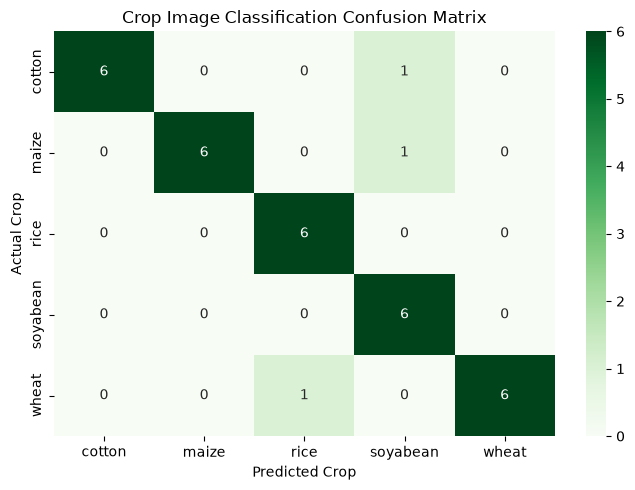

In [5]:
y_true, y_prob = [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_prob.extend(preds)
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = np.argmax(y_prob, axis=1)

print('=== OFFLINE TEST SET EVALUATION METRICS ===')
print(f'1. Accuracy:             {accuracy_score(y_true, y_pred):.4f}')
print(f'2. Cross-Entropy Loss:   {log_loss(y_true, y_prob):.4f}')
print(f'3. Precision (Weighted): {precision_score(y_true, y_pred, average="weighted"):.4f}')
print(f'4. Recall (Weighted):    {recall_score(y_true, y_pred, average="weighted"):.4f}')
print(f'5. F1-Score (Weighted):  {f1_score(y_true, y_pred, average="weighted"):.4f}')
print('\nClassification Report:\n', classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.title('Crop Image Classification Confusion Matrix')
plt.xlabel('Predicted Crop')
plt.ylabel('Actual Crop')
plt.tight_layout()
plt.show()